In [1]:
import duckdb
con = duckdb.connect("../data/processed/retail.duckdb", read_only=True)

FOODS products in store CA_1 that sell a few units a day on average

In [2]:
con.sql("""
    SELECT item_id, SUM(units) AS total_units,
           ROUND(AVG(units), 2) AS avg_per_day,
           MAX(units) AS max_day
    FROM raw.sales
    WHERE store_id = 'CA_1' AND cat_id = 'FOODS' 
    GROUP BY item_id
    HAVING AVG(units) BETWEEN 4 AND 8
    ORDER BY item_id
    LIMIT 10
""")

┌─────────────┬─────────────┬─────────────┬─────────┐
│   item_id   │ total_units │ avg_per_day │ max_day │
│   varchar   │   int128    │   double    │  int32  │
├─────────────┼─────────────┼─────────────┼─────────┤
│ FOODS_1_019 │        7957 │         4.1 │      27 │
│ FOODS_1_032 │       14863 │        7.66 │      72 │
│ FOODS_1_043 │       12837 │        6.61 │      59 │
│ FOODS_1_046 │       13839 │        7.13 │      46 │
│ FOODS_1_086 │       10704 │        5.51 │      23 │
│ FOODS_1_099 │       13232 │        6.82 │      59 │
│ FOODS_1_110 │        9259 │        4.77 │      34 │
│ FOODS_2_013 │        7978 │        4.11 │      18 │
│ FOODS_2_016 │        8967 │        4.62 │      39 │
│ FOODS_2_021 │       12538 │        6.46 │      41 │
└─────────────┴─────────────┴─────────────┴─────────┘
  10 rows                                 4 columns

In [3]:
con.sql("""
    SELECT s.item_id,
           ROUND(AVG(s.units), 2) AS avg_per_day,
           MAX(s.units)           AS max_day
    FROM raw.sales s
    WHERE s.store_id = 'CA_1' AND s.cat_id = 'FOODS'
      AND s.item_id IN (SELECT item_id FROM raw.prices
                        WHERE store_id = 'CA_1' AND wm_yr_wk = 11101)
    GROUP BY s.item_id
    HAVING AVG(s.units) BETWEEN 4 AND 8
    ORDER BY s.item_id
    LIMIT 10
""")

┌─────────────┬─────────────┬─────────┐
│   item_id   │ avg_per_day │ max_day │
│   varchar   │   double    │  int32  │
├─────────────┼─────────────┼─────────┤
│ FOODS_1_019 │         4.1 │      27 │
│ FOODS_1_032 │        7.66 │      72 │
│ FOODS_1_046 │        7.13 │      46 │
│ FOODS_1_086 │        5.51 │      23 │
│ FOODS_2_013 │        4.11 │      18 │
│ FOODS_2_021 │        6.46 │      41 │
│ FOODS_2_128 │        7.52 │      52 │
│ FOODS_2_181 │         6.3 │      22 │
│ FOODS_2_293 │        4.51 │      29 │
│ FOODS_2_299 │         5.3 │      26 │
└─────────────┴─────────────┴─────────┘
  10 rows                   3 columns

In [4]:
item = "FOODS_1_019"  

df = con.execute("""
    SELECT c.date, s.units
    FROM raw.sales s
    JOIN raw.calendar c USING (d)
    WHERE s.store_id = 'CA_1' AND s.item_id = ?
    ORDER BY c.date
""", [item]).df()

df.head(60)

,date,units
0,2011-01-29,15
1,2011-01-30,9
2,2011-01-31,6
3,2011-02-01,0
4,2011-02-02,3
5,2011-02-03,3
6,2011-02-04,3
7,2011-02-05,16
8,2011-02-06,6
9,2011-02-07,5


In [5]:
print("days:", len(df))
print("average per day:", round(df.units.mean(), 2))
print("max in one day:", df.units.max())
print("share of zero days:", round((df.units == 0).mean(), 3))

days: 1941
average per day: 4.1
max in one day: 27
share of zero days: 0.47


In [6]:
item = "FOODS_2_016"   

con.execute("""
    SELECT c.wm_yr_wk,
           MIN(c.date)    AS week_start,
           SUM(s.units)   AS units,
           MAX(p.sell_price) AS price
    FROM raw.calendar c
    LEFT JOIN raw.sales  s ON s.d = c.d
                          AND s.store_id = 'CA_1' AND s.item_id = ?
    LEFT JOIN raw.prices p ON p.wm_yr_wk = c.wm_yr_wk
                          AND p.store_id = 'CA_1' AND p.item_id = ?
    WHERE c.date BETWEEN '2011-01-29' AND '2011-04-09'
    GROUP BY c.wm_yr_wk
    ORDER BY c.wm_yr_wk
""", [item, item]).df()

,wm_yr_wk,week_start,units,price
0,11101,2011-01-29,0.0,NaN
1,11102,2011-02-05,0.0,NaN
2,11103,2011-02-12,0.0,NaN
3,11104,2011-02-19,0.0,NaN
4,11105,2011-02-26,0.0,NaN
5,11106,2011-03-05,0.0,NaN
6,11107,2011-03-12,0.0,NaN
7,11108,2011-03-19,0.0,NaN
8,11109,2011-03-26,0.0,NaN
9,11110,2011-04-02,0.0,NaN


Price is empty (NULL), units 0: the product was not on sale. It was removed or delisted, so there was no stockout.

Load the engine


In [7]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")
from simulation.engine import simulate_product

get this product’s ordering terms:

In [8]:
pack_size, moq_packs, review_days, z, lead_days = con.execute("""
    SELECT i.pack_size, i.moq_packs, i.review_days, i.z, s.quoted_lead_days
    FROM sim.item_supply i
    JOIN sim.supplier s USING (supplier_id)
    WHERE i.item_id = ?
""", [item]).fetchone()

print(pack_size, moq_packs, review_days, z, lead_days)

6 2 1 1.6449 2


run the simulation:

In [9]:
demand = df.units.tolist()
sim = simulate_product(demand, lead_days, review_days, pack_size, moq_packs, z)
sim.head(15)

,day,demand,received,sold,lost_sales,expired,shrunk,record_error,count_adjustment,end_stock,system_stock,ordered,on_order
0,0,15,0,15,0,0,0,0,0,81,81,0,0
1,1,9,0,9,0,0,0,0,0,72,72,0,0
2,2,6,0,6,0,0,0,0,0,66,66,0,0
3,3,0,0,0,0,0,0,0,0,66,66,0,0
4,4,3,0,3,0,0,0,0,0,63,63,0,0
5,5,3,0,3,0,0,0,0,0,60,60,0,0
6,6,3,0,3,0,0,0,0,0,57,57,0,0
7,7,16,0,16,0,0,0,0,0,41,41,0,0
8,8,6,0,6,0,0,0,0,0,35,35,0,0
9,9,5,0,5,0,0,0,0,0,30,30,0,0


the summary:

In [10]:
print("share of demand lost:", round(sim.lost_sales.sum() / sim.demand.sum(), 4))
print("share of days with a stockout:", round((sim.lost_sales > 0).mean(), 4))
print("average end-of-day stock:", round(sim.end_stock.mean(), 1))
print("number of orders:", (sim.ordered > 0).sum())

share of demand lost: 0.0245
share of days with a stockout: 0.0206
average end-of-day stock: 23.3
number of orders: 431


- 2.45% of demand lost	About 1 customer in 40 left empty-handed. That is low but not zero, which is what we want.

- Stockouts on 2.06% of days	About 40 days out of 1,941 had at least one lost sale.

- Average stock 23.3	The product sells 4.1 a day, so the shelf holds about 5–6 days of sales.

- 431 orders	One order about every 4–5 days. Over the whole run this is roughly 18 units per order, about 3 packs.

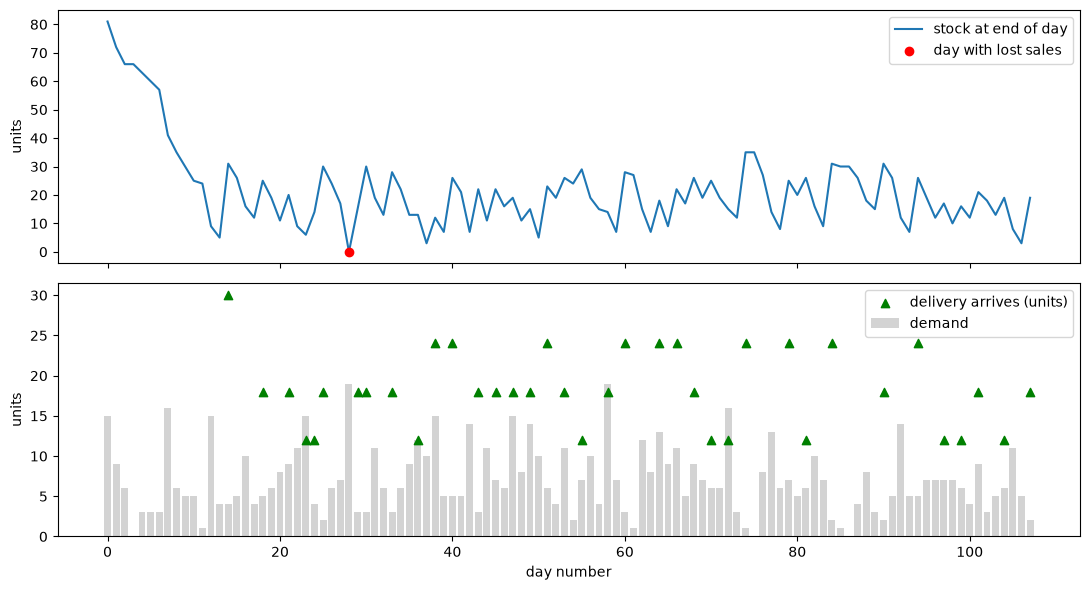

In [11]:
import matplotlib.pyplot as plt

first = sim.index[sim.lost_sales > 0][0]          # first stockout day
w = sim.iloc[max(first - 40, 0): first + 80]      # a window around it

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

ax[0].plot(w.day, w.end_stock, label="stock at end of day")
lost = w[w.lost_sales > 0]
ax[0].scatter(lost.day, lost.end_stock, color="red", zorder=3, label="day with lost sales")
ax[0].set_ylabel("units")
ax[0].legend()

ax[1].bar(w.day, w.demand, color="lightgray", label="demand")
arr = w[w.received > 0]
ax[1].scatter(arr.day, arr.received, color="green", marker="^", label="delivery arrives (units)")
ax[1].set_xlabel("day number")
ax[1].set_ylabel("units")
ax[1].legend()

plt.tight_layout()
plt.show()

read the supplier’s rates:

In [12]:
import numpy as np
import yaml

with open("../config.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
fill_range = tuple(cfg["simulation"]["partial_fill_range"])

late_rate, partial_rate = con.execute("""
    SELECT s.late_rate, s.partial_rate
    FROM sim.item_supply i
    JOIN sim.supplier s USING (supplier_id)
    WHERE i.item_id = ?
""", [item]).fetchone()

print("late_rate:", late_rate, "| partial_rate:", partial_rate)

late_rate: 0.089 | partial_rate: 0.048


four scenarios, 20 seeds each:

In [13]:
def run(late, partial, seed):
    out = simulate_product(
        demand, lead_days, review_days, pack_size, moq_packs, z,
        late_rate=late, partial_rate=partial, partial_fill_range=fill_range,
        rng=np.random.default_rng(seed),
    )
    return out.lost_sales.sum() / out.demand.sum(), (out.lost_sales > 0).mean()

scenarios = {
    "perfect suppliers": (0, 0),
    "only late":         (late_rate, 0),
    "only partial":      (0, partial_rate),
    "late + partial":    (late_rate, partial_rate),
}

for name, (late, partial) in scenarios.items():
    results = np.array([run(late, partial, seed) for seed in range(20)])
    lost, stockout_days = results.mean(axis=0)
    print(f"{name:18s} demand lost: {lost:.2%}   days with stockout: {stockout_days:.2%}")

perfect suppliers  demand lost: 2.45%   days with stockout: 2.06%
only late          demand lost: 4.84%   days with stockout: 3.46%
only partial       demand lost: 2.42%   days with stockout: 1.95%
late + partial     demand lost: 4.95%   days with stockout: 3.54%


In [20]:
with open("../config.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

losses = cfg["simulation"]["losses"]
category = item.split("_")[0]              # FOODS, HOUSEHOLD or HOBBIES
expiry = losses["expiry_rate"][category]
shrink = losses["shrink_rate"]
rec_err = losses["record_error_rate"]
count_days = losses["count_every_days"]

def run2(expiry_rate, shrink_rate, record_error_rate, seed):
    out = simulate_product(
        demand, lead_days, review_days, pack_size, moq_packs, z,
        late_rate=late_rate, partial_rate=partial_rate, partial_fill_range=fill_range,
        expiry_rate=expiry_rate, shrink_rate=shrink_rate,
        record_error_rate=record_error_rate, count_every_days=count_days,
        rng=np.random.default_rng(seed),
        loss_rng=np.random.default_rng(seed + 1000),
    )
    return (out.lost_sales.sum() / out.demand.sum(),
            (out.lost_sales > 0).mean(),
            out.end_stock.mean(),
            out.expired.sum())

scenarios = {
    "Day 7 (no losses)":           (0, 0, 0),
    "Day 8 (all losses)":          (expiry, shrink, rec_err),
    "only expiry":                 (expiry, 0, 0),
    "shrink 20x (thought test)":   (0, shrink * 20, 0),
}

for name, (e, s, r) in scenarios.items():
    res = np.array([run2(e, s, r, seed) for seed in range(20)]).mean(axis=0)
    print(f"{name:27s} lost: {res[0]:.2%}  stockout days: {res[1]:.2%}  "
          f"avg shelf: {res[2]:.1f}  expired units: {res[3]:.0f}")

Day 7 (no losses)           lost: 4.95%  stockout days: 3.54%  avg shelf: 22.8  expired units: 0
Day 8 (all losses)          lost: 5.40%  stockout days: 3.77%  avg shelf: 16.1  expired units: 125
only expiry                 lost: 5.16%  stockout days: 3.70%  avg shelf: 16.2  expired units: 128
shrink 20x (thought test)   lost: 6.15%  stockout days: 4.24%  avg shelf: 14.9  expired units: 0


In [15]:
common = dict(
    late_rate=late_rate, partial_rate=partial_rate, partial_fill_range=fill_range,
)
a = simulate_product(demand, lead_days, review_days, pack_size, moq_packs, z, **common,
                     rng=np.random.default_rng(0), loss_rng=np.random.default_rng(1000))
b = simulate_product(demand, lead_days, review_days, pack_size, moq_packs, z, **common,
                     expiry_rate=expiry,
                     rng=np.random.default_rng(0), loss_rng=np.random.default_rng(1000))

print("expiry rate used:", expiry)
print("orders placed:", (a.ordered > 0).sum(), (b.ordered > 0).sum())
print("units ordered:", a.ordered.sum(), b.ordered.sum())
print("expired units:", a.expired.sum(), b.expired.sum())
print("average shelf:", round(a.end_stock.mean(), 1), round(b.end_stock.mean(), 1))
print("system minus shelf (mean abs):", (b.system_stock - b.end_stock).abs().mean())
print(a.end_stock.describe().round(1))
print(b.end_stock.describe().round(1))

expiry rate used: 0.004
orders placed: 429 426
units ordered: 7506 7578
expired units: 0 112
average shelf: 22.1 16.0
system minus shelf (mean abs): 0.0
count    1941.0
mean       22.1
std        10.4
min         0.0
25%        15.0
50%        26.0
75%        30.0
max        81.0
Name: end_stock, dtype: float64
count    1941.0
mean       16.0
std         9.2
min         0.0
25%        10.0
50%        14.0
75%        22.0
max        81.0
Name: end_stock, dtype: float64


In [16]:
import pandas as pd

zero = pd.Series(demand) == 0
streak = zero.groupby((~zero).cumsum()).cumsum()   # days in a row without any demand
idle = streak >= 14                                 # days inside a 14+ day idle stretch

print("longest run of days with no demand:", streak.max())
print("days inside idle stretches:", idle.sum(), "of", len(idle))
print("average shelf on idle days:      without expiry", round(a.end_stock[idle].mean(), 1),
      "| with expiry", round(b.end_stock[idle].mean(), 1))
print("average shelf on the other days: without expiry", round(a.end_stock[~idle].mean(), 1),
      "| with expiry", round(b.end_stock[~idle].mean(), 1))

longest run of days with no demand: 742
days inside idle stretches: 729 of 1941
average shelf on idle days:      without expiry 30.0 | with expiry 14.2
average shelf on the other days: without expiry 17.4 | with expiry 17.2


In [17]:
end_idx = int(streak.idxmax())                  # last day of the longest idle stretch
start_idx = end_idx - int(streak.max()) + 1     # first day of it
start_date = df.date[start_idx].date()
end_date = df.date[end_idx].date()
print("longest idle stretch:", start_date, "to", end_date)

weeks = con.execute("""
    SELECT c.wm_yr_wk, MIN(c.date) AS week_start, MAX(p.sell_price) AS price
    FROM raw.calendar c
    LEFT JOIN raw.prices p ON p.wm_yr_wk = c.wm_yr_wk
                          AND p.store_id = 'CA_1' AND p.item_id = ?
    WHERE c.date BETWEEN ? AND ?
    GROUP BY c.wm_yr_wk
    ORDER BY c.wm_yr_wk
""", [item, start_date, end_date]).df()

print("weeks in the stretch:", len(weeks))
print("weeks WITH a price:", weeks.price.notna().sum())

longest idle stretch: 2013-09-25 to 2015-10-06
weeks in the stretch: 107
weeks WITH a price: 107


We are going to use FOODS_2_016, the product that wasn’t on sale until after April 2011. To see the problem on the late-launch.

In [18]:
item2 = "FOODS_2_016"

df2 = con.execute("""
    SELECT c.date, s.units
    FROM raw.sales s
    JOIN raw.calendar c USING (d)
    WHERE s.store_id = 'CA_1' AND s.item_id = ?
    ORDER BY c.date
""", [item2]).df()
demand2 = df2.units.tolist()

first_sale = int(np.argmax(np.array(demand2) > 0))
print("first sale on day:", first_sale)

sim2 = simulate_product(demand2, lead_days, review_days, pack_size, moq_packs, z,
                        expiry_rate=0.004)

before = sim2[sim2.day < first_sale]
print("orders placed before the first sale:", (before.ordered > 0).sum())
print("units ordered before the first sale:", before.ordered.sum())
print("units expired before the first sale:", before.expired.sum())
print("average shelf before the first sale:", round(before.end_stock.mean(), 1))

first sale on day: 190
orders placed before the first sale: 2
units ordered before the first sale: 24
units expired before the first sale: 10
average shelf before the first sale: 12.8


Testing the engine after adding the on_sale to make sure that a product is being sold or not

In [19]:
item2 = "FOODS_2_016"

df2 = con.execute("""
    SELECT c.date, s.units, (p.sell_price IS NOT NULL) AS on_sale
    FROM raw.sales s
    JOIN raw.calendar c USING (d)
    LEFT JOIN raw.prices p ON p.wm_yr_wk = c.wm_yr_wk
                          AND p.store_id = s.store_id AND p.item_id = s.item_id
    WHERE s.store_id = 'CA_1' AND s.item_id = ?
    ORDER BY c.date
""", [item2]).df()
demand2 = df2.units.tolist()
on_sale2 = df2.on_sale.tolist()

dept = con.execute("SELECT dept_id FROM raw.sales WHERE item_id = ? LIMIT 1", [item2]).fetchone()[0]
launch_mu = con.execute("""
    SELECT AVG(s.units)
    FROM raw.sales s
    JOIN raw.calendar c USING (d)
    JOIN raw.prices p ON p.wm_yr_wk = c.wm_yr_wk
                     AND p.store_id = s.store_id AND p.item_id = s.item_id
    WHERE s.store_id = 'CA_1' AND s.dept_id = ?
""", [dept]).fetchone()[0]
print("department:", dept, "| average daily demand when on sale:", round(launch_mu, 2))

old = simulate_product(demand2, lead_days, review_days, pack_size, moq_packs, z,
                       expiry_rate=0.004)
new = simulate_product(demand2, lead_days, review_days, pack_size, moq_packs, z,
                       on_sale=on_sale2, launch_mu=launch_mu, expiry_rate=0.004)

off = ~df2.on_sale
print("days not on sale:", int(off.sum()))
print("average shelf on those days:  old", round(old.end_stock[off].mean(), 1),
      "| new", round(new.end_stock[off].mean(), 1))
print("units ordered on those days:  old", old.ordered[off].sum(),
      "| new", new.ordered[off].sum())
print("units expired in total:       old", old.expired.sum(), "| new", new.expired.sum())
print(new[new.opening > 0][["day", "opening"]])

department: FOODS_2 | average daily demand when on sale: 1.45
days not on sale: 189
average shelf on those days:  old 12.8 | new 0.0
units ordered on those days:  old 24 | new 0
units expired in total:       old 143 | new 131
     day  opening
189  189       24
